#1. What is SVM?
Support Vector Machine (SVM) is a supervised Machine Learning algorithm used for:
1. Classification – Predicting categories.
2. Regression – Predicting numerical values.

#2. Understand SVM with an example
Imagine we have two categories of students:
- Group A
   Students who pass.
- Group B
   Students who fail.

SVM tries to find the best boundary (called a Hyperplane) that separates these two groups.

#3. Important SVM terminology
Term	Meaning
Hyperplane	Decision boundary separating classes
Support Vectors	Data points closest to the boundary
Margin	Distance between the boundary and nearest points
Kernel	Helps SVM handle non-linear data
C Parameter	Controls the trade-off between margin size and classification errors

Mind Template:
- SVM → Find the best separating boundary.
- Support Vectors → Closest points to boundary.
- Margin → Separation distance.
- Kernel → Handle complex boundaries.

#Today's Practical Plan
We'll use the Breast Cancer Wisconsin dataset from Scikit-learn.
1. Load the dataset.
2. Understand features and target.
3. Split training and testing data.
4. Apply feature scaling.
5. Train SVM classification models.
6. Evaluate using accuracy, precision, recall and F1-score.
7. Compare Linear and RBF kernels.
8. Visualize the confusion matrix.

#Practical — Code Cell 1

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer

# Load Breast Cancer dataset
cancer = load_breast_cancer()

# Create DataFrame
df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

# Add target column
df["Diagnosis"] = cancer.target

print("Dataset Loaded Successfully!")

print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Shape:", df.shape)

print("\nTarget Classes:")
print(cancer.target_names)

Dataset Loaded Successfully!

First 5 Rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  w

#Step 2: Separate Features and Target

In [2]:
# Separate features and target

X = df.drop("Diagnosis", axis=1)
y = df["Diagnosis"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nDiagnosis Distribution:")
print(y.value_counts())

Features Shape: (569, 30)
Target Shape: (569,)

Diagnosis Distribution:
Diagnosis
1    357
0    212
Name: count, dtype: int64


#Step 3: Train-Test Split

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (455, 30)
Testing Features: (114, 30)

Training Target: (455,)
Testing Target: (114,)


#Step 4: Feature Scaling

In [4]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Original Training Shape:", X_train.shape)
print("Scaled Training Shape:", X_train_scaled.shape)

print("\nFirst 5 Scaled Rows:")
print(X_train_scaled[:5])

Original Training Shape: (455, 30)
Scaled Training Shape: (455, 30)

First 5 Scaled Rows:
[[-1.07200079e+00 -6.58424598e-01 -1.08808010e+00 -9.39273639e-01
  -1.35939882e-01 -1.00871795e+00 -9.68358632e-01 -1.10203235e+00
   2.81062120e-01 -1.13231479e-01 -7.04860874e-01 -4.40938351e-01
  -7.43948977e-01 -6.29804931e-01  7.48061001e-04 -9.91572979e-01
  -6.93759567e-01 -9.83284458e-01 -5.91579010e-01 -4.28972052e-01
  -1.03409427e+00 -6.23497432e-01 -1.07077336e+00 -8.76534437e-01
  -1.69982346e-01 -1.03883630e+00 -1.07899452e+00 -1.35052668e+00
  -3.52658049e-01 -5.41380026e-01]
 [ 1.74874285e+00  6.65017334e-02  1.75115682e+00  1.74555856e+00
   1.27446827e+00  8.42288215e-01  1.51985232e+00  1.99466430e+00
  -2.93045055e-01 -3.20179716e-01  1.27567198e-01 -3.81382677e-01
   9.40746962e-02  3.17524379e-01  6.39656015e-01  8.73892616e-02
   7.08450758e-01  1.18215034e+00  4.26212305e-01  7.47970186e-02
   1.22834212e+00 -9.28334970e-02  1.18746742e+00  1.10438613e+00
   1.51700092e+00

#Step 5: Train SVM Classification Model

In [5]:
from sklearn.svm import SVC

# Create Linear SVM model
svm_linear = SVC(
    kernel="linear",
    C=1.0
)

# Train the model
svm_linear.fit(X_train_scaled, y_train)

print("Linear SVM Model Trained Successfully!")
print("Kernel:", svm_linear.kernel)
print("C Parameter:", svm_linear.C)

Linear SVM Model Trained Successfully!
Kernel: linear
C Parameter: 1.0


#Step 6: Make Predictions

In [6]:
# Predict using Linear SVM
y_pred_linear = svm_linear.predict(X_test_scaled)

# Compare actual and predicted values
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_linear
})

print("First 10 Predictions:")
print(results.head(10))

First 10 Predictions:
   Actual  Predicted
0       0          0
1       1          1
2       0          0
3       1          0
4       0          0
5       1          1
6       1          1
7       0          0
8       0          0
9       0          0


#Step 7: Model Evaluation

In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred_linear)
precision = precision_score(y_test, y_pred_linear)
recall = recall_score(y_test, y_pred_linear)
f1 = f1_score(y_test, y_pred_linear)

print("Linear SVM Evaluation")
print("---------------------")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Linear SVM Evaluation
---------------------
Accuracy: 0.9736842105263158
Precision: 0.9859154929577465
Recall: 0.9722222222222222
F1 Score: 0.9790209790209791


#Step 9: Confusion Matrix

Confusion Matrix:
[[41  1]
 [ 2 70]]


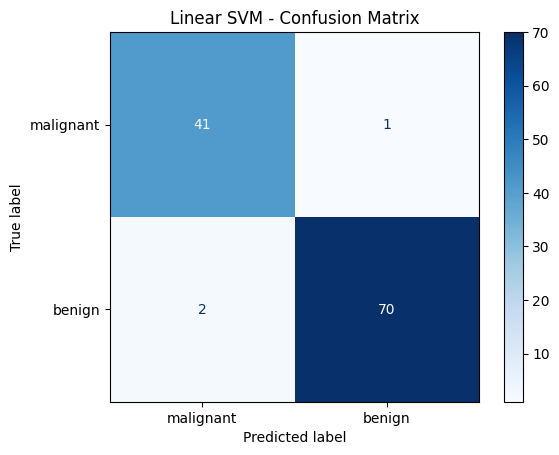

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_linear)

print("Confusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=cancer.target_names
)

display.plot(cmap="Blues")
plt.title("Linear SVM - Confusion Matrix")
plt.show()

#Step 10: Train RBF Kernel SVM

In [9]:
# Create RBF SVM model
svm_rbf = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

# Train the model
svm_rbf.fit(X_train_scaled, y_train)

print("RBF SVM Model Trained Successfully!")
print("Kernel:", svm_rbf.kernel)
print("C Parameter:", svm_rbf.C)
print("Gamma:", svm_rbf.gamma)

RBF SVM Model Trained Successfully!
Kernel: rbf
C Parameter: 1.0
Gamma: scale


#Step 11: RBF Predictions

In [10]:
# Predict using RBF SVM
y_pred_rbf = svm_rbf.predict(X_test_scaled)

# Compare actual and predicted values
rbf_results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_rbf
})

print("First 10 RBF Predictions:")
print(rbf_results.head(10))

First 10 RBF Predictions:
   Actual  Predicted
0       0          0
1       1          1
2       0          0
3       1          1
4       0          0
5       1          1
6       1          1
7       0          0
8       0          0
9       0          0


#Step 12: Evaluate RBF SVM

In [11]:
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
precision_rbf = precision_score(y_test, y_pred_rbf)
recall_rbf = recall_score(y_test, y_pred_rbf)
f1_rbf = f1_score(y_test, y_pred_rbf)

print("RBF SVM Evaluation")
print("------------------")
print("Accuracy:", accuracy_rbf)
print("Precision:", precision_rbf)
print("Recall:", recall_rbf)
print("F1 Score:", f1_rbf)

RBF SVM Evaluation
------------------
Accuracy: 0.9824561403508771
Precision: 0.9861111111111112
Recall: 0.9861111111111112
F1 Score: 0.9861111111111112


#Step 13: Visualize Model Comparison

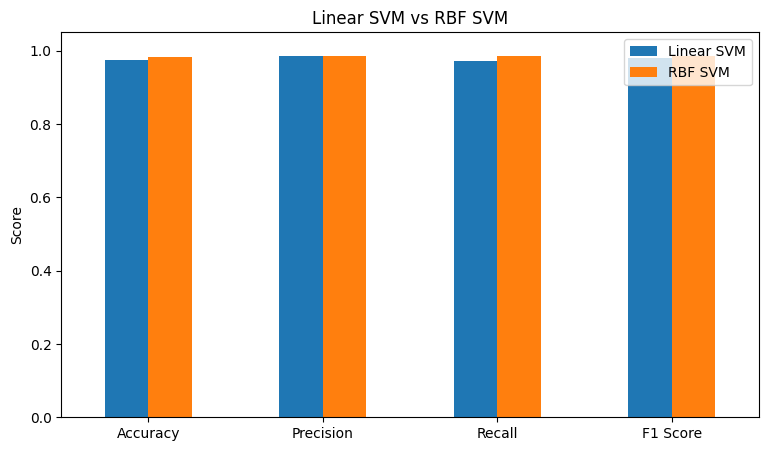

In [12]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

linear_scores = [
    accuracy,
    precision,
    recall,
    f1
]

rbf_scores = [
    accuracy_rbf,
    precision_rbf,
    recall_rbf,
    f1_rbf
]

comparison = pd.DataFrame({
    "Linear SVM": linear_scores,
    "RBF SVM": rbf_scores
}, index=metrics)

comparison.plot(kind="bar", figsize=(9, 5))

plt.title("Linear SVM vs RBF SVM")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend()
plt.show()